# Thesis Experiments: Effect of Data Preprocessing on ML-Based IDS
## NSL-KDD Dataset - All 6 Experiment Sets
**Place the notebook in the same folder as `KDDTrain+.txt` and `KDDTest+.txt`**

Runs 120 model evaluations (20 experimental settings × 3 classifiers × 2 classification scenarios) and saves results to results_summary.xlsx.


In [ ]:
from pathlib import Path
import os

try:
    # Google Colab environment
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/NSL_KDD_Experiments')

except ImportError:
    # Local Jupyter environment
    # Dataset files should be in the notebook folder
    pass

print("Working directory:", Path.cwd())

## 1. Import Libraries

In [ ]:
pip install xgboost imbalanced-learn openpyxl matplotlib scikit-learn pandas numpy

In [ ]:
# Standard libraries
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Scikit-learn
from sklearn.preprocessing import (LabelEncoder, OneHotEncoder,
                                    MinMaxScaler, StandardScaler,
                                    RobustScaler, Normalizer)
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score,
                              recall_score, f1_score, roc_auc_score,
                              confusion_matrix, classification_report)

# XGBoost
from xgboost import XGBClassifier

# Imbalanced-learn
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Output
import openpyxl

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("All libraries loaded successfully.")

All libraries loaded successfully.


## 2. Load and Inspect NSL-KDD Dataset

In [ ]:
# Column names for NSL-KDD (41 features + label + difficulty)
col_names = [
    'duration','protocol_type','service','flag','src_bytes','dst_bytes',
    'land','wrong_fragment','urgent','hot','num_failed_logins','logged_in',
    'num_compromised','root_shell','su_attempted','num_root','num_file_creations',
    'num_shells','num_access_files','num_outbound_cmds','is_host_login',
    'is_guest_login','count','srv_count','serror_rate','srv_serror_rate',
    'rerror_rate','srv_rerror_rate','same_srv_rate','diff_srv_rate',
    'srv_diff_host_rate','dst_host_count','dst_host_srv_count',
    'dst_host_same_srv_rate','dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate','dst_host_srv_diff_host_rate',
    'dst_host_serror_rate','dst_host_srv_serror_rate',
    'dst_host_rerror_rate','dst_host_srv_rerror_rate',
    'label','difficulty'
]

train_df = pd.read_csv('KDDTrain+.txt', names=col_names)
test_df  = pd.read_csv('KDDTest+.txt',  names=col_names)

# Drop difficulty column (not a feature)
train_df.drop('difficulty', axis=1, inplace=True)
test_df.drop('difficulty',  axis=1, inplace=True)

print(f"Training set : {train_df.shape[0]:,} records x {train_df.shape[1]} columns")
print(f"Test set     : {test_df.shape[0]:,} records x {test_df.shape[1]} columns")
print(f"\nTraining label distribution:")
print(train_df['label'].value_counts())

Training set : 125,973 records x 42 columns
Test set     : 22,544 records x 42 columns

Training label distribution:
label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64


## 3. Label Mapping (Binary and Multiclass)

In [ ]:
# Binary: normal=0, attack=1
# Multiclass: normal=0, DoS=1, Probe=2, R2L=3, U2R=4

DOS_ATTACKS = [
    'back','land','neptune','pod','smurf','teardrop','apache2','udpstorm',
    'processtable','worm','mailbomb'
]
PROBE_ATTACKS = ['ipsweep','nmap','portsweep','satan','mscan','saint']
R2L_ATTACKS = [
    'ftp_write','guess_passwd','imap','multihop','phf','spy','warezclient',
    'warezmaster','sendmail','named','snmpgetattack','snmpguess','xlock',
    'xsnoop','httptunnel'
]
U2R_ATTACKS = ['buffer_overflow','loadmodule','perl','rootkit','ps','sqlattack','xterm']

def map_binary(label):
    return 0 if label == 'normal' else 1

def map_multiclass(label):
    if label == 'normal':      return 0
    elif label in DOS_ATTACKS:   return 1
    elif label in PROBE_ATTACKS: return 2
    elif label in R2L_ATTACKS:   return 3
    elif label in U2R_ATTACKS:   return 4
    else:                        return 1   # unseen attacks → DoS bucket

train_df['binary_label']     = train_df['label'].apply(map_binary)
train_df['multiclass_label'] = train_df['label'].apply(map_multiclass)
test_df['binary_label']      = test_df['label'].apply(map_binary)
test_df['multiclass_label']  = test_df['label'].apply(map_multiclass)

print("Binary label distribution (train):")
print(train_df['binary_label'].value_counts().rename({0:'Normal',1:'Attack'}))
print("\nMulticlass label distribution (train):")
mc = train_df['multiclass_label'].value_counts().rename(
    {0:'Normal',1:'DoS',2:'Probe',3:'R2L',4:'U2R'})
print(mc)

Binary label distribution (train):
binary_label
Normal    67343
Attack    58630
Name: count, dtype: int64

Multiclass label distribution (train):
multiclass_label
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64


## 4. Helper Functions

In [ ]:
CAT_COLS = ['protocol_type', 'service', 'flag']
NUM_COLS = [c for c in train_df.columns
            if c not in CAT_COLS + ['label','binary_label','multiclass_label']]

def get_base_features(df):
    """Return feature matrix before encoding (categorical still as strings)."""
    return df[NUM_COLS + CAT_COLS].copy()

def apply_label_encoding(X_train, X_test):
    """Label-encode the 3 categorical columns."""
    X_tr = X_train.copy()
    X_te = X_test.copy()
    for col in CAT_COLS:
        le = LabelEncoder()
        le.fit(X_tr[col])
        # Handle unseen categories in test by mapping to 0
        X_tr[col] = le.transform(X_tr[col])
        X_te[col] = X_te[col].map(
            lambda x: le.transform([x])[0] if x in le.classes_ else 0)
    return X_tr.astype(float), X_te.astype(float)

def apply_ohe(X_train, X_test):
    """One-hot-encode the 3 categorical columns."""
    X_tr_num = X_train[NUM_COLS].copy().astype(float)
    X_te_num = X_test[NUM_COLS].copy().astype(float)
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    ohe.fit(X_train[CAT_COLS])
    tr_cat = ohe.transform(X_train[CAT_COLS])
    te_cat = ohe.transform(X_test[CAT_COLS])
    X_tr = np.hstack([X_tr_num.values, tr_cat])
    X_te = np.hstack([X_te_num.values, te_cat])
    return X_tr, X_te

def evaluate(y_true, y_pred, y_prob=None, multiclass=False):
    """Return dict of metrics."""
    avg = 'macro' if multiclass else 'binary'
    res = {
        'Accuracy' : round(accuracy_score(y_true, y_pred), 4),
        'Precision': round(precision_score(y_true, y_pred, average=avg,
                                           zero_division=0), 4),
        'Recall'   : round(recall_score(y_true, y_pred, average=avg,
                                        zero_division=0), 4),
        'F1-Score' : round(f1_score(y_true, y_pred, average=avg,
                                    zero_division=0), 4),
    }
    if y_prob is not None:
        try:
            mc_arg = 'ovr' if multiclass else 'raise'
            res['ROC-AUC'] = round(
                roc_auc_score(y_true, y_prob,
                              multi_class=mc_arg if multiclass else None,
                              average='macro' if multiclass else None), 4)
        except Exception:
            res['ROC-AUC'] = None
    else:
        res['ROC-AUC'] = None
    if not multiclass:
        cm = confusion_matrix(y_true, y_pred)
        tn, fp = cm[0,0], cm[0,1]
        res['FAR'] = round(fp/(fp+tn), 4) if (fp+tn) > 0 else 0.0
    return res

def run_classifiers(X_train, y_train, X_test, y_test, multiclass=False):
    """Train RF, XGB, kNN and return results dict."""
    clfs = {
        'RandomForest': RandomForestClassifier(n_estimators=100,
                                               random_state=RANDOM_STATE,
                                               n_jobs=-1),
        'XGBoost'     : XGBClassifier(n_estimators=100, learning_rate=0.3,
                                       max_depth=6, random_state=RANDOM_STATE,
                                       use_label_encoder=False,
                                       eval_metric='mlogloss' if multiclass
                                                   else 'logloss',
                                       verbosity=0, n_jobs=-1),
        'kNN'         : KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    }
    out = {}
    for name, clf in clfs.items():
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        try:
            if multiclass:
                y_prob = clf.predict_proba(X_test)
            else:
                y_prob = clf.predict_proba(X_test)[:, 1]
        except Exception:
            y_prob = None
        out[name] = evaluate(y_test, y_pred, y_prob, multiclass)
    return out

print("Helper functions defined.")

Helper functions defined.


## 5. Results Collector

In [ ]:
all_results = []   # will hold one dict per row

def store(exp_set, variant, classifier, scenario, metrics):
    row = {
        'Exp Set'   : exp_set,
        'Variant'   : variant,
        'Classifier': classifier,
        'Scenario'  : scenario,
    }
    row.update(metrics)
    all_results.append(row)
    flag = '★' if metrics.get('F1-Score', 0) >= 0.95 else ''
    print(f"  {classifier:<15} | F1={metrics.get('F1-Score','N/A')} "
          f"Acc={metrics.get('Accuracy','N/A')} {flag}")

print("Results collector ready.")

Results collector ready.


## 6. Unprocessed Baseline (Label Encoding only)

In [ ]:
print("=== BASELINE: Label Encoding only ===")

X_tr_raw = get_base_features(train_df)
X_te_raw = get_base_features(test_df)
X_tr_le, X_te_le = apply_label_encoding(X_tr_raw, X_te_raw)

for scenario, (y_tr, y_te) in [
    ('Binary',     (train_df['binary_label'],     test_df['binary_label'])),
    ('Multiclass', (train_df['multiclass_label'], test_df['multiclass_label']))
]:
    mc = (scenario == 'Multiclass')
    print(f"  [{scenario}]")
    res = run_classifiers(X_tr_le, y_tr, X_te_le, y_te, multiclass=mc)
    for clf, m in res.items():
        store('0-Baseline', 'Label Encoding only', clf, scenario, m)

print("Baseline complete.")

=== BASELINE: Label Encoding only ===
  [Binary]
  RandomForest    | F1=0.7482 Acc=0.7661 
  XGBoost         | F1=0.8006 Acc=0.8064 
  kNN             | F1=0.7578 Acc=0.7728 
  [Multiclass]
  RandomForest    | F1=0.516 Acc=0.7638 
  XGBoost         | F1=0.5412 Acc=0.7603 
  kNN             | F1=0.4873 Acc=0.7265 
Baseline complete.


## 7. Experiment Set 1 — Feature Scaling

In [ ]:
print("=== EXP SET 1: Feature Scaling ===")

scalers = {
    'No Scaling'  : None,
    'MinMax'      : MinMaxScaler(),
    'Standard'    : StandardScaler(),
    'Robust'      : RobustScaler(),
    'Normalizer'  : Normalizer(),
}

X_tr_raw = get_base_features(train_df)
X_te_raw = get_base_features(test_df)
X_tr_le, X_te_le = apply_label_encoding(X_tr_raw, X_te_raw)

for scaler_name, scaler in scalers.items():
    print(f"\n  -- {scaler_name} --")
    if scaler is None:
        X_tr_s, X_te_s = X_tr_le.copy(), X_te_le.copy()
    else:
        scaler.fit(X_tr_le)
        X_tr_s = pd.DataFrame(scaler.transform(X_tr_le),
                              columns=X_tr_le.columns)
        X_te_s = pd.DataFrame(scaler.transform(X_te_le),
                              columns=X_te_le.columns)
    for scenario, (y_tr, y_te) in [
        ('Binary',     (train_df['binary_label'],     test_df['binary_label'])),
        ('Multiclass', (train_df['multiclass_label'], test_df['multiclass_label']))
    ]:
        mc = (scenario == 'Multiclass')
        print(f"    [{scenario}]")
        res = run_classifiers(X_tr_s, y_tr, X_te_s, y_te, multiclass=mc)
        for clf, m in res.items():
            store('1-Feature Scaling', scaler_name, clf, scenario, m)

print("\nExp Set 1 complete.")

=== EXP SET 1: Feature Scaling ===

  -- No Scaling --
    [Binary]
  RandomForest    | F1=0.7482 Acc=0.7661 
  XGBoost         | F1=0.8006 Acc=0.8064 
  kNN             | F1=0.7578 Acc=0.7728 
    [Multiclass]
  RandomForest    | F1=0.516 Acc=0.7638 
  XGBoost         | F1=0.5412 Acc=0.7603 
  kNN             | F1=0.4873 Acc=0.7265 

  -- MinMax --
    [Binary]
  RandomForest    | F1=0.7481 Acc=0.766 
  XGBoost         | F1=0.8006 Acc=0.8064 
  kNN             | F1=0.7606 Acc=0.7763 
    [Multiclass]
  RandomForest    | F1=0.5212 Acc=0.7639 
  XGBoost         | F1=0.5412 Acc=0.7603 
  kNN             | F1=0.5644 Acc=0.7566 

  -- Standard --
    [Binary]
  RandomForest    | F1=0.7489 Acc=0.7666 
  XGBoost         | F1=0.8006 Acc=0.8064 
  kNN             | F1=0.7492 Acc=0.7676 
    [Multiclass]
  RandomForest    | F1=0.5214 Acc=0.7641 
  XGBoost         | F1=0.5412 Acc=0.7603 
  kNN             | F1=0.5498 Acc=0.7496 

  -- Robust --
    [Binary]
  RandomForest    | F1=0.7481 Acc=0.76

## 8. Experiment Set 2 — Categorical Encoding

In [ ]:
print("=== EXP SET 2: Categorical Encoding ===")

X_tr_raw = get_base_features(train_df)
X_te_raw = get_base_features(test_df)

encodings = {
    'Label Encoding': apply_label_encoding(X_tr_raw, X_te_raw),
    'One-Hot Encoding': apply_ohe(X_tr_raw, X_te_raw),
}

scaler = StandardScaler()

for enc_name, (X_tr_enc, X_te_enc) in encodings.items():
    print(f"\n  -- {enc_name} (feature dims: {X_tr_enc.shape[1]}) --")
    scaler.fit(X_tr_enc)
    X_tr_s = scaler.transform(X_tr_enc)
    X_te_s = scaler.transform(X_te_enc)
    for scenario, (y_tr, y_te) in [
        ('Binary',     (train_df['binary_label'],     test_df['binary_label'])),
        ('Multiclass', (train_df['multiclass_label'], test_df['multiclass_label']))
    ]:
        mc = (scenario == 'Multiclass')
        print(f"    [{scenario}]")
        res = run_classifiers(X_tr_s, y_tr, X_te_s, y_te, multiclass=mc)
        for clf, m in res.items():
            store('2-Categorical Encoding', enc_name, clf, scenario, m)

print("\nExp Set 2 complete.")

=== EXP SET 2: Categorical Encoding ===

  -- Label Encoding (feature dims: 41) --
    [Binary]
  RandomForest    | F1=0.7489 Acc=0.7666 
  XGBoost         | F1=0.8006 Acc=0.8064 
  kNN             | F1=0.7492 Acc=0.7676 
    [Multiclass]
  RandomForest    | F1=0.5214 Acc=0.7641 
  XGBoost         | F1=0.5412 Acc=0.7603 
  kNN             | F1=0.5498 Acc=0.7496 

  -- One-Hot Encoding (feature dims: 122) --
    [Binary]
  RandomForest    | F1=0.7462 Acc=0.7648 
  XGBoost         | F1=0.7946 Acc=0.8018 
  kNN             | F1=0.7635 Acc=0.7704 
    [Multiclass]
  RandomForest    | F1=0.4819 Acc=0.7502 
  XGBoost         | F1=0.5717 Acc=0.7741 
  kNN             | F1=0.5454 Acc=0.746 

Exp Set 2 complete.


## 9. Experiment Set 3 — Feature Selection

In [ ]:
print("=== EXP SET 3: Feature Selection ===")

X_tr_raw = get_base_features(train_df)
X_te_raw = get_base_features(test_df)
X_tr_le, X_te_le = apply_label_encoding(X_tr_raw, X_te_raw)

scaler = StandardScaler()
scaler.fit(X_tr_le)
X_tr_scaled = pd.DataFrame(scaler.transform(X_tr_le), columns=X_tr_le.columns)
X_te_scaled = pd.DataFrame(scaler.transform(X_te_le), columns=X_te_le.columns)

y_tr_bin = train_df['binary_label']

# Correlation-based selection (train only)
corr_matrix = X_tr_scaled.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
drop_cols = [col for col in upper.columns if any(upper[col] > 0.95)]
X_tr_corr = X_tr_scaled.drop(columns=drop_cols)
X_te_corr = X_te_scaled.drop(columns=drop_cols)
print(f"  Correlation-based: dropped {len(drop_cols)} features, "
      f"kept {X_tr_corr.shape[1]}")

selections = {
    'All Features (41)': (X_tr_scaled.values, X_te_scaled.values),
    'PCA (n=20)'       : None,
    'SelectKBest (k=20)': None,
    'Correlation (r>0.95)': (X_tr_corr.values, X_te_corr.values),
}

# PCA — fit on train only (needs non-negative for chi2, so use abs for SelectKBest)
pca = PCA(n_components=20, random_state=RANDOM_STATE)
pca.fit(X_tr_scaled)
selections['PCA (n=20)'] = (pca.transform(X_tr_scaled), pca.transform(X_te_scaled))

# SelectKBest with chi2 requires non-negative — use MinMax first
mm = MinMaxScaler()
mm.fit(X_tr_le)
X_tr_mm = mm.transform(X_tr_le)
X_te_mm = mm.transform(X_te_le)
skb = SelectKBest(chi2, k=20)
skb.fit(X_tr_mm, y_tr_bin)
selections['SelectKBest (k=20)'] = (skb.transform(X_tr_mm), skb.transform(X_te_mm))

for sel_name, (X_tr_s, X_te_s) in selections.items():
    print(f"\n  -- {sel_name} (dims: {X_tr_s.shape[1]}) --")
    for scenario, (y_tr, y_te) in [
        ('Binary',     (train_df['binary_label'],     test_df['binary_label'])),
        ('Multiclass', (train_df['multiclass_label'], test_df['multiclass_label']))
    ]:
        mc = (scenario == 'Multiclass')
        print(f"    [{scenario}]")
        res = run_classifiers(X_tr_s, y_tr, X_te_s, y_te, multiclass=mc)
        for clf, m in res.items():
            store('3-Feature Selection', sel_name, clf, scenario, m)

print("\nExp Set 3 complete.")

=== EXP SET 3: Feature Selection ===
  Correlation-based: dropped 6 features, kept 35

  -- All Features (41) (dims: 41) --
    [Binary]
  RandomForest    | F1=0.7489 Acc=0.7666 
  XGBoost         | F1=0.8006 Acc=0.8064 
  kNN             | F1=0.7492 Acc=0.7676 
    [Multiclass]
  RandomForest    | F1=0.5214 Acc=0.7641 
  XGBoost         | F1=0.5412 Acc=0.7603 
  kNN             | F1=0.5498 Acc=0.7496 

  -- PCA (n=20) (dims: 20) --
    [Binary]
  RandomForest    | F1=0.7469 Acc=0.7661 
  XGBoost         | F1=0.7494 Acc=0.7675 
  kNN             | F1=0.7439 Acc=0.7635 
    [Multiclass]
  RandomForest    | F1=0.5305 Acc=0.7442 
  XGBoost         | F1=0.5238 Acc=0.7441 
  kNN             | F1=0.5424 Acc=0.7445 

  -- SelectKBest (k=20) (dims: 20) --
    [Binary]
  RandomForest    | F1=0.7346 Acc=0.756 
  XGBoost         | F1=0.7553 Acc=0.7712 
  kNN             | F1=0.775 Acc=0.7869 
    [Multiclass]
  RandomForest    | F1=0.488 Acc=0.7323 
  XGBoost         | F1=0.5087 Acc=0.7409 
  kNN

## 10. Experiment Set 4 — Class Imbalance Handling

In [ ]:
print("=== EXP SET 4: Class Imbalance Handling ===")

X_tr_raw = get_base_features(train_df)
X_te_raw = get_base_features(test_df)
X_tr_le, X_te_le = apply_label_encoding(X_tr_raw, X_te_raw)

scaler = StandardScaler()
scaler.fit(X_tr_le)
X_tr_s = scaler.transform(X_tr_le)
X_te_s = scaler.transform(X_te_le)

for scenario, (y_tr_orig, y_te) in [
    ('Binary',     (train_df['binary_label'].values,
                    test_df['binary_label'])),
    ('Multiclass', (train_df['multiclass_label'].values,
                    test_df['multiclass_label']))
]:
    mc = (scenario == 'Multiclass')
    print(f"\n  [{scenario}]")

    imbalance_methods = {'No Handling': (X_tr_s.copy(), y_tr_orig.copy())}

    # SMOTE — train only
    try:
        sm = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
        X_sm, y_sm = sm.fit_resample(X_tr_s, y_tr_orig)
        imbalance_methods['SMOTE'] = (X_sm, y_sm)
        print(f"    SMOTE resampled: {len(y_sm):,} records")
    except Exception as e:
        print(f"    SMOTE failed: {e}")

    # Random Undersampling — train only
    try:
        rus = RandomUnderSampler(random_state=RANDOM_STATE)
        X_rus, y_rus = rus.fit_resample(X_tr_s, y_tr_orig)
        imbalance_methods['Random Undersampling'] = (X_rus, y_rus)
        print(f"    RUS resampled: {len(y_rus):,} records")
    except Exception as e:
        print(f"    RUS failed: {e}")

    # Class Weights (built into classifiers)
    imbalance_methods['Class Weights'] = (X_tr_s.copy(), y_tr_orig.copy())

    for method_name, (X_tr_m, y_tr_m) in imbalance_methods.items():
        print(f"\n    -- {method_name} --")
        if method_name == 'Class Weights':
            clfs = {
                'RandomForest': RandomForestClassifier(
                    n_estimators=100, class_weight='balanced',
                    random_state=RANDOM_STATE, n_jobs=-1),
                'XGBoost'     : XGBClassifier(
                    n_estimators=100, learning_rate=0.3, max_depth=6,
                    scale_pos_weight=(
                        (y_tr_m == 0).sum() / (y_tr_m == 1).sum()
                        if not mc else 1),
                    random_state=RANDOM_STATE,
                    eval_metric='mlogloss' if mc else 'logloss',
                    verbosity=0, n_jobs=-1),
                'kNN'         : KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
            }
            for clf_name, clf in clfs.items():
                clf.fit(X_tr_m, y_tr_m)
                y_pred = clf.predict(X_te_s)
                try:
                    y_prob = (clf.predict_proba(X_te_s) if mc
                              else clf.predict_proba(X_te_s)[:, 1])
                except Exception:
                    y_prob = None
                m = evaluate(y_te, y_pred, y_prob, multiclass=mc)
                store('4-Class Imbalance', method_name, clf_name, scenario, m)
                print(f"      {clf_name:<15} | F1={m.get('F1-Score','N/A')}")
        else:
            res = run_classifiers(X_tr_m, y_tr_m, X_te_s, y_te, multiclass=mc)
            for clf, m in res.items():
                store('4-Class Imbalance', method_name, clf, scenario, m)

print("\nExp Set 4 complete.")

=== EXP SET 4: Class Imbalance Handling ===

  [Binary]
    SMOTE resampled: 134,686 records
    RUS resampled: 117,260 records

    -- No Handling --
  RandomForest    | F1=0.7489 Acc=0.7666 
  XGBoost         | F1=0.8006 Acc=0.8064 
  kNN             | F1=0.7492 Acc=0.7676 

    -- SMOTE --
  RandomForest    | F1=0.7464 Acc=0.7647 
  XGBoost         | F1=0.7957 Acc=0.8027 
  kNN             | F1=0.7497 Acc=0.7679 

    -- Random Undersampling --
  RandomForest    | F1=0.7481 Acc=0.7659 
  XGBoost         | F1=0.7933 Acc=0.8006 
  kNN             | F1=0.7508 Acc=0.7686 

    -- Class Weights --
  RandomForest    | F1=0.7443 Acc=0.7634 
      RandomForest    | F1=0.7443
  XGBoost         | F1=0.7974 Acc=0.8039 
      XGBoost         | F1=0.7974
  kNN             | F1=0.7492 Acc=0.7676 
      kNN             | F1=0.7492

  [Multiclass]
    SMOTE resampled: 336,715 records
    RUS resampled: 260 records

    -- No Handling --
  RandomForest    | F1=0.5214 Acc=0.7641 
  XGBoost         | 

## 11. Experiment Set 5 — Outlier Removal

In [ ]:
print("=== EXP SET 5: Outlier Removal ===")

X_tr_raw = get_base_features(train_df)
X_te_raw = get_base_features(test_df)
X_tr_le, X_te_le = apply_label_encoding(X_tr_raw, X_te_raw)

y_tr_bin = train_df['binary_label'].reset_index(drop=True)
y_tr_mc  = train_df['multiclass_label'].reset_index(drop=True)
y_te_bin = test_df['binary_label']
y_te_mc  = test_df['multiclass_label']

X_tr_le = X_tr_le.reset_index(drop=True)

outlier_sets = {}

# (a) No removal
outlier_sets['No Removal'] = (X_tr_le.copy(), y_tr_bin.copy(), y_tr_mc.copy())

# (b) IQR-based — use 3x IQR threshold (safer for skewed IDS data)
Q1  = X_tr_le.quantile(0.25)
Q3  = X_tr_le.quantile(0.75)
IQR = Q3 - Q1
active_cols = IQR[IQR > 0].index
mask_iqr = pd.Series([True] * len(X_tr_le))
for col in active_cols:
    col_mask = ((X_tr_le[col] >= Q1[col] - 3.0 * IQR[col]) &
                (X_tr_le[col] <= Q3[col] + 3.0 * IQR[col]))
    mask_iqr = mask_iqr & col_mask

kept_pct = mask_iqr.sum() / len(mask_iqr) * 100
print(f"  IQR removal: {mask_iqr.sum():,} records kept ({100-kept_pct:.1f}% removed)")

if mask_iqr.sum() < 100:
    print("  WARNING: IQR removed too many records — skipping")
else:
    X_tr_iqr   = X_tr_le[mask_iqr].reset_index(drop=True)
    y_tr_b_iqr = y_tr_bin[mask_iqr].reset_index(drop=True)
    y_tr_m_iqr = y_tr_mc[mask_iqr].reset_index(drop=True)
    outlier_sets['IQR-based (3xIQR)'] = (X_tr_iqr, y_tr_b_iqr, y_tr_m_iqr)

# (c) Z-score-based (threshold=3)
std_cols = X_tr_le.std()
active_z = std_cols[std_cols > 0].index
z_scores = (X_tr_le[active_z] - X_tr_le[active_z].mean()) / X_tr_le[active_z].std()
mask_z = (z_scores.abs() < 3).all(axis=1)

kept_pct_z = mask_z.sum() / len(mask_z) * 100
print(f"  Z-score removal: {mask_z.sum():,} records kept ({100-kept_pct_z:.1f}% removed)")

if mask_z.sum() < 100:
    print("  WARNING: Z-score removed too many records — skipping")
else:
    X_tr_z   = X_tr_le[mask_z].reset_index(drop=True)
    y_tr_b_z = y_tr_bin[mask_z].reset_index(drop=True)
    y_tr_m_z = y_tr_mc[mask_z].reset_index(drop=True)
    outlier_sets['Z-score (thr=3)'] = (X_tr_z, y_tr_b_z, y_tr_m_z)

for out_name, (X_tr_o, y_tr_b, y_tr_m) in outlier_sets.items():
    print(f"\n  -- {out_name} (training size: {len(X_tr_o):,}) --")
    sc = StandardScaler()
    sc.fit(X_tr_o)
    X_tr_s = sc.transform(X_tr_o)
    X_te_s = sc.transform(X_te_le)

    for scenario, (y_tr, y_te) in [
        ('Binary',     (y_tr_b, y_te_bin)),
        ('Multiclass', (y_tr_m, y_te_mc))
    ]:
        mc = (scenario == 'Multiclass')
        print(f"    [{scenario}]")
        res = run_classifiers(X_tr_s, y_tr, X_te_s, y_te, multiclass=mc)
        for clf, m in res.items():
            store('5-Outlier Removal', out_name, clf, scenario, m)

print("\nExp Set 5 complete.")

=== EXP SET 5: Outlier Removal ===
  IQR removal: 67,486 records kept (46.4% removed)
  Z-score removal: 103,118 records kept (18.1% removed)

  -- No Removal (training size: 125,973) --
    [Binary]
  RandomForest    | F1=0.7489 Acc=0.7666 
  XGBoost         | F1=0.8006 Acc=0.8064 
  kNN             | F1=0.7492 Acc=0.7676 
    [Multiclass]
  RandomForest    | F1=0.5214 Acc=0.7641 
  XGBoost         | F1=0.5412 Acc=0.7603 
  kNN             | F1=0.5498 Acc=0.7496 

  -- IQR-based (3xIQR) (training size: 67,486) --
    [Binary]
  RandomForest    | F1=0.649 Acc=0.6991 
  XGBoost         | F1=0.6789 Acc=0.7179 
  kNN             | F1=0.7131 Acc=0.7337 
    [Multiclass]
  RandomForest    | F1=0.3433 Acc=0.649 
  XGBoost         | F1=0.385 Acc=0.6799 
  kNN             | F1=0.3628 Acc=0.6651 

  -- Z-score (thr=3) (training size: 103,118) --
    [Binary]
  RandomForest    | F1=0.7627 Acc=0.778 
  XGBoost         | F1=0.7769 Acc=0.7885 
  kNN             | F1=0.7164 Acc=0.7453 
    [Multicla

## 12. Experiment Set 6 — Optimised Combined Pipeline

> **Note:** Run this cell after reviewing the results from Sets 1–5.
> Replace `BEST_SCALER`, `BEST_ENCODING`, `BEST_SELECTION`, `BEST_IMBALANCE`, `BEST_OUTLIER`
> with the technique that gave the highest F1-Score in each category.

In [ ]:
print("=== EXP SET 6: Optimised Combined Pipeline ===")

# ── STEP 1: Load fresh ──────────────────────────────────────────────────────
X_tr_raw = get_base_features(train_df)
X_te_raw = get_base_features(test_df)

# ── STEP 2: Outlier removal ─────────────────────────────────────────────────
BEST_OUTLIER = 'none'

if BEST_OUTLIER == 'iqr':
    Q1 = X_tr_raw.select_dtypes('number').quantile(0.25)
    Q3 = X_tr_raw.select_dtypes('number').quantile(0.75)
    IQR = Q3 - Q1
    mask = ~((X_tr_raw.select_dtypes('number') < (Q1 - 3.0 * IQR)) |
              (X_tr_raw.select_dtypes('number') > (Q3 + 3.0 * IQR))).any(axis=1)
    X_tr_raw = X_tr_raw[mask].reset_index(drop=True)
    y_tr_bin_opt = train_df['binary_label'][mask].reset_index(drop=True)
    y_tr_mc_opt  = train_df['multiclass_label'][mask].reset_index(drop=True)
elif BEST_OUTLIER == 'zscore':
    num_only = X_tr_raw.select_dtypes('number')
    z = (num_only - num_only.mean()) / num_only.std()
    mask = (z.abs() < 3).all(axis=1)
    X_tr_raw = X_tr_raw[mask].reset_index(drop=True)
    y_tr_bin_opt = train_df['binary_label'][mask].reset_index(drop=True)
    y_tr_mc_opt  = train_df['multiclass_label'][mask].reset_index(drop=True)
else:
    y_tr_bin_opt = train_df['binary_label'].reset_index(drop=True)
    y_tr_mc_opt  = train_df['multiclass_label'].reset_index(drop=True)

# ── STEP 3: Encoding ────────────────────────────────────────────────────────
BEST_ENCODING = 'label'

if BEST_ENCODING == 'ohe':
    X_tr_enc, X_te_enc = apply_ohe(X_tr_raw, X_te_raw)
else:
    X_tr_enc, X_te_enc = apply_label_encoding(X_tr_raw, X_te_raw)

# ── STEP 4: Scaling ─────────────────────────────────────────────────────────
BEST_SCALER = 'minmax'

scalers_map = {
    'standard'  : StandardScaler(),
    'minmax'    : MinMaxScaler(),
    'robust'    : RobustScaler(),
    'normalizer': Normalizer(),
    'none'      : None,
}
sc = scalers_map[BEST_SCALER]
if sc is not None:
    sc.fit(X_tr_enc)
    X_tr_scaled = sc.transform(X_tr_enc)
    X_te_scaled = sc.transform(X_te_enc)
else:
    X_tr_scaled = X_tr_enc.values if hasattr(X_tr_enc, 'values') else X_tr_enc
    X_te_scaled = X_te_enc.values if hasattr(X_te_enc, 'values') else X_te_enc

# ── STEP 5: Feature Selection ────────────────────────────────────────────────
BEST_SELECTION = 'correlation'

if BEST_SELECTION == 'pca':
    pca2 = PCA(n_components=20, random_state=RANDOM_STATE)
    pca2.fit(X_tr_scaled)
    X_tr_sel = pca2.transform(X_tr_scaled)
    X_te_sel = pca2.transform(X_te_scaled)

elif BEST_SELECTION == 'selectkbest':
    X_tr_enc_vals = X_tr_enc.values if hasattr(X_tr_enc, 'values') else X_tr_enc
    X_te_enc_vals = X_te_enc.values if hasattr(X_te_enc, 'values') else X_te_enc
    mm2 = MinMaxScaler()
    mm2.fit(X_tr_enc_vals)
    X_tr_mm2 = mm2.transform(X_tr_enc_vals)
    X_te_mm2 = mm2.transform(X_te_enc_vals)
    skb2 = SelectKBest(chi2, k=20)
    skb2.fit(X_tr_mm2, y_tr_bin_opt)
    X_tr_sel = skb2.transform(X_tr_mm2)
    X_te_sel = skb2.transform(X_te_mm2)

elif BEST_SELECTION == 'correlation':
    X_tr_df_tmp = pd.DataFrame(X_tr_scaled)
    X_te_df_tmp = pd.DataFrame(X_te_scaled)
    corr2  = X_tr_df_tmp.corr().abs()
    upper2 = corr2.where(np.triu(np.ones(corr2.shape), k=1).astype(bool))
    drop2  = [col for col in upper2.columns if any(upper2[col] > 0.95)]
    X_tr_sel = X_tr_df_tmp.drop(columns=drop2).values
    X_te_sel = X_te_df_tmp.drop(columns=drop2).values
    print(f"  Correlation selection: dropped {len(drop2)} features, "
          f"kept {X_tr_sel.shape[1]}")

else:
    X_tr_sel = X_tr_scaled if isinstance(X_tr_scaled, np.ndarray) else X_tr_scaled.values
    X_te_sel = X_te_scaled if isinstance(X_te_scaled, np.ndarray) else X_te_scaled.values

print(f"  Optimised pipeline feature dimensions: {X_tr_sel.shape[1]}")

# ── STEP 6: Class Imbalance ──────────────────────────────────────────────────
BEST_IMBALANCE = 'none'

def run_opt(X_tr, y_tr, X_te, y_te, scenario, imbalance='none'):
    mc = (scenario == 'Multiclass')
    if imbalance == 'smote':
        sm2 = SMOTE(random_state=RANDOM_STATE)
        X_tr, y_tr = sm2.fit_resample(X_tr, y_tr)
        print(f"    SMOTE applied: {len(y_tr):,} records")
    elif imbalance == 'rus':
        rus2 = RandomUnderSampler(random_state=RANDOM_STATE)
        X_tr, y_tr = rus2.fit_resample(X_tr, y_tr)
        print(f"    RUS applied: {len(y_tr):,} records")
    return run_classifiers(X_tr, y_tr, X_te, y_te, multiclass=mc)

variant_label = (f'Scaler={BEST_SCALER} | Enc={BEST_ENCODING} | '
                 f'Sel={BEST_SELECTION} | Imb={BEST_IMBALANCE} | '
                 f'Outlier={BEST_OUTLIER}')

for scenario, (y_tr, y_te) in [
    ('Binary',     (y_tr_bin_opt.values, test_df['binary_label'])),
    ('Multiclass', (y_tr_mc_opt.values,  test_df['multiclass_label']))
]:
    print(f"\n  [Optimised Pipeline — {scenario}]")
    res = run_opt(X_tr_sel.copy(), y_tr, X_te_sel, y_te,
                  scenario, BEST_IMBALANCE)
    for clf, m in res.items():
        store('6-Optimised Pipeline', variant_label, clf, scenario, m)

print("\nExp Set 6 complete.")
print(f"\nPipeline used: {variant_label}")

=== EXP SET 6: Optimised Combined Pipeline ===
  Correlation selection: dropped 6 features, kept 35
  Optimised pipeline feature dimensions: 35

  [Optimised Pipeline — Binary]
  RandomForest    | F1=0.767 Acc=0.7802 
  XGBoost         | F1=0.7942 Acc=0.8014 
  kNN             | F1=0.7715 Acc=0.7845 

  [Optimised Pipeline — Multiclass]
  RandomForest    | F1=0.5011 Acc=0.7446 
  XGBoost         | F1=0.5361 Acc=0.7624 
  kNN             | F1=0.5632 Acc=0.762 

Exp Set 6 complete.

Pipeline used: Scaler=minmax | Enc=label | Sel=correlation | Imb=none | Outlier=none


## 13. Results Summary and Export

In [ ]:
# Build results DataFrame
df_results = pd.DataFrame(all_results)

# Display full table
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 140)
print(df_results.to_string(index=False))

               Exp Set                                                               Variant   Classifier   Scenario  Accuracy  Precision  Recall  F1-Score  ROC-AUC    FAR
            0-Baseline                                                   Label Encoding only RandomForest     Binary    0.7661     0.9663  0.6105    0.7482      NaN 0.0281
            0-Baseline                                                   Label Encoding only      XGBoost     Binary    0.8064     0.9678  0.6826    0.8006      NaN 0.0300
            0-Baseline                                                   Label Encoding only          kNN     Binary    0.7728     0.9638  0.6243    0.7578      NaN 0.0310
            0-Baseline                                                   Label Encoding only RandomForest Multiclass    0.7638     0.8181  0.5040    0.5160   0.9092    NaN
            0-Baseline                                                   Label Encoding only      XGBoost Multiclass    0.7603     0.8092  0

In [ ]:
# Save to Excel with formatting
with pd.ExcelWriter('results_summary.xlsx', engine='openpyxl') as writer:

    # Sheet 1: All results
    df_results.to_excel(writer, sheet_name='All Results', index=False)

    # Sheet per experiment set
    for exp_set in df_results['Exp Set'].unique():
        subset = df_results[df_results['Exp Set'] == exp_set]
        sheet_name = exp_set[:31]  # Excel limit
        subset.to_excel(writer, sheet_name=sheet_name, index=False)

    # Summary pivot: best F1 per exp set x classifier x scenario
    if 'F1-Score' in df_results.columns:
        pivot = df_results.pivot_table(
            values='F1-Score',
            index=['Exp Set', 'Variant'],
            columns=['Classifier', 'Scenario'],
            aggfunc='mean'
        ).round(4)
        pivot.to_excel(writer, sheet_name='F1 Pivot')

print("Results saved to results_summary.xlsx")
print(f"Total model runs: {len(df_results)}")

Results saved to results_summary.xlsx
Total model runs: 120


In [ ]:
# Quick best-per-category summary
print("\n=== BEST F1-SCORE PER EXPERIMENT SET (Binary) ===")
binary = df_results[df_results['Scenario'] == 'Binary']
for exp_set in sorted(binary['Exp Set'].unique()):
    sub = binary[binary['Exp Set'] == exp_set]
    best_idx = sub['F1-Score'].idxmax()
    best = sub.loc[best_idx]
    print(f"  {exp_set:<30} | Best: {best['Variant']:<30} "
          f"| Clf: {best['Classifier']:<15} | F1: {best['F1-Score']}")

print("\n=== BEST F1-SCORE PER EXPERIMENT SET (Multiclass) ===")
mc_df = df_results[df_results['Scenario'] == 'Multiclass']
for exp_set in sorted(mc_df['Exp Set'].unique()):
    sub = mc_df[mc_df['Exp Set'] == exp_set]
    best_idx = sub['F1-Score'].idxmax()
    best = sub.loc[best_idx]
    print(f"  {exp_set:<30} | Best: {best['Variant']:<30} "
          f"| Clf: {best['Classifier']:<15} | F1: {best['F1-Score']}")


=== BEST F1-SCORE PER EXPERIMENT SET (Binary) ===
  0-Baseline                     | Best: Label Encoding only            | Clf: XGBoost         | F1: 0.8006
  1-Feature Scaling              | Best: No Scaling                     | Clf: XGBoost         | F1: 0.8006
  2-Categorical Encoding         | Best: Label Encoding                 | Clf: XGBoost         | F1: 0.8006
  3-Feature Selection            | Best: All Features (41)              | Clf: XGBoost         | F1: 0.8006
  4-Class Imbalance              | Best: No Handling                    | Clf: XGBoost         | F1: 0.8006
  5-Outlier Removal              | Best: No Removal                     | Clf: XGBoost         | F1: 0.8006
  6-Optimised Pipeline           | Best: Scaler=minmax | Enc=label | Sel=correlation | Imb=none | Outlier=none | Clf: XGBoost         | F1: 0.7942

=== BEST F1-SCORE PER EXPERIMENT SET (Multiclass) ===
  0-Baseline                     | Best: Label Encoding only            | Clf: XGBoost         | F1

## 14. Confusion Matrices for Baseline

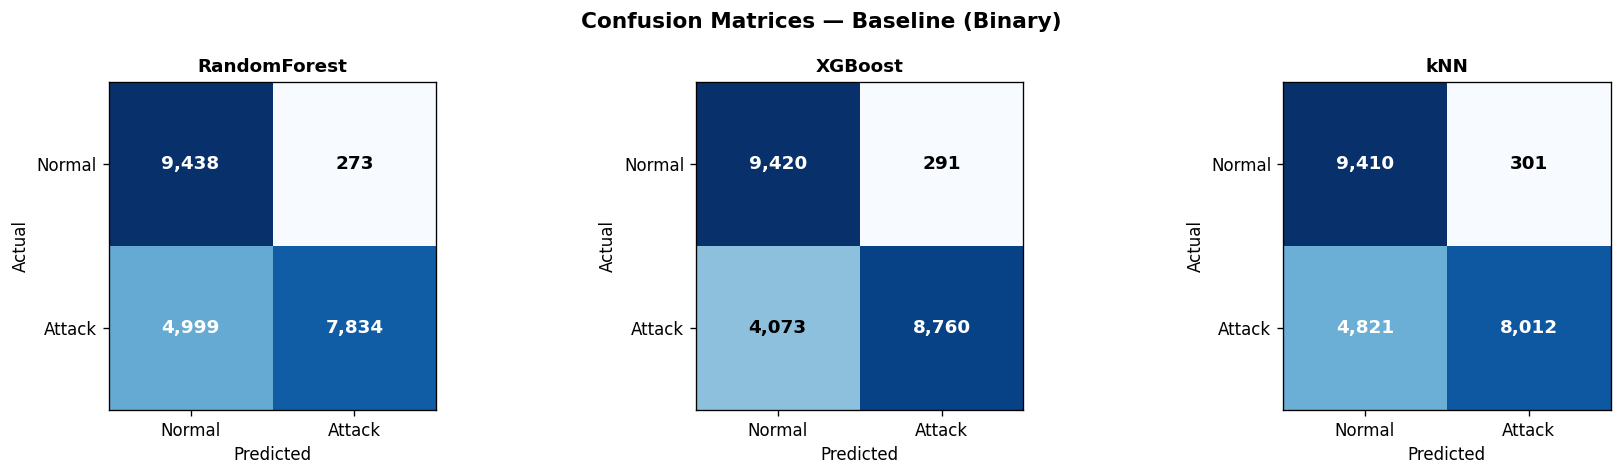

Saved: confusion_matrices_baseline.png


In [ ]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

# Re-run baseline for confusion matrix plots
X_tr_raw = get_base_features(train_df)
X_te_raw = get_base_features(test_df)
X_tr_le, X_te_le = apply_label_encoding(X_tr_raw, X_te_raw)

clfs_plot = {
    'RandomForest': RandomForestClassifier(n_estimators=100,
                                           random_state=RANDOM_STATE, n_jobs=-1),
    'XGBoost'     : XGBClassifier(n_estimators=100, learning_rate=0.3,
                                   max_depth=6, random_state=RANDOM_STATE,
                                   eval_metric='logloss', verbosity=0, n_jobs=-1),
    'kNN'         : KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
}

y_tr = train_df['binary_label']
y_te = test_df['binary_label']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Confusion Matrices — Baseline (Binary)', fontsize=13, fontweight='bold')

for ax, (name, clf) in zip(axes, clfs_plot.items()):
    clf.fit(X_tr_le, y_tr)
    y_pred = clf.predict(X_te_le)
    cm = confusion_matrix(y_te, y_pred)
    im = ax.imshow(cm, cmap='Blues')
    ax.set_title(name, fontsize=11, fontweight='bold')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    ax.set_xticks([0,1]); ax.set_yticks([0,1])
    ax.set_xticklabels(['Normal','Attack'])
    ax.set_yticklabels(['Normal','Attack'])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i,j]:,}', ha='center', va='center',
                    color='white' if cm[i,j] > cm.max()/2 else 'black',
                    fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('confusion_matrices_baseline.png', bbox_inches='tight')
plt.show()
print("Saved: confusion_matrices_baseline.png")